# 🏦 Banking Contagion & Liquidity Explosion: Silicon Valley Bank (SVB) Collapse (March 2023)
## Central Bank Emergency Intervention & Vertical Spike Dynamics

### 1. Incident Background
On **March 8–10, 2023**, Silicon Valley Bank (SVB) suffered the largest and fastest bank run in US financial history, with depositors attempting to withdraw \$42 billion in a single day. Regulators seized the bank on March 10, and Signature Bank collapsed days later.
* To prevent systemic banking collapse, the Federal Reserve invoked Section 13(3) emergency lending powers, opening the **Bank Term Funding Program (BTFP)** and opening the Discount Window.

### 2. Target Variable ($y$)
* **`WLCFLL`** (Federal Reserve Total Loans to Depository Institutions, \$ Millions):
  * Baseline (March 8, 2023): **\$15,209 Million** (\$15.2 Billion).
  * Post-Incident Crest (March 22, 2023): **\$354,191 Million** (\$354.2 Billion).
  * **+2,228% sudden vertical spike in 14 days**, dwarfing even the initial 2008 Lehman Brothers shock speed.

### 3. Data Source
* Federal Reserve Bank of St. Louis (**FRED**) Weekly H.4.1 Release.
* Series ID: `WLCFLL`.


### 📚 Academic Citations & Benchmark Lineage
* **Academic Paper:** Jiang, E., Matvos, G., Piskorski, T., & Seru, A. (2023). *"Monetary Tightening and U.S. Bank Fragility in 2023: Mark-to-Market Losses and Uninsured Depositor Runs?"* *National Bureau of Economic Research (NBER)*, Working Paper No. 31048.
* **Federal Reserve Release:** Federal Reserve Board of Governors H.4.1 Statistical Release (FRED `WLCFLL`).
* **BibTeX Citation:**
```bibtex
@techreport{jiang2023monetary,
  title={Monetary Tightening and U.S. Bank Fragility in 2023: Mark-to-Market Losses and Uninsured Depositor Runs?},
  author={Jiang, Erica Xuewei and Matvos, Gregor and Piskorski, Tomasz and Seru, Amit},
  institution={National Bureau of Economic Research},
  type={Working Paper},
  number={31048},
  year={2023}
}
```

In [1]:
import os
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
os.makedirs('data', exist_ok=True)
print("Environment initialized.")

Environment initialized.


### 4. Data Ingestion from FRED

In [2]:
def fetch_fed_loans(cache_dir='data'):
    cache_path = os.path.join(cache_dir, 'fed_loans_raw.csv')
    
    if os.path.exists(cache_path):
        print(f"Loading Fed loan series from cache: {cache_path}")
        df = pd.read_csv(cache_path)
    else:
        print("Downloading weekly Fed emergency lending data from FRED...")
        url = 'https://fred.stlouisfed.org/graph/fredgraph.csv?id=WLCFLL'
        df = pd.read_csv(url)
        df.to_csv(cache_path, index=False)
        print(f"Downloaded and cached {len(df)} observations.")
        
    return df

df_fed_raw = fetch_fed_loans()
df_fed_raw.head()

Downloaded and cached 1245 observations.


,observation_date,WLCFLL
0,2002-12-18,45
1,2002-12-25,59
2,2003-01-01,40
3,2003-01-08,18
4,2003-01-15,15


### 5. Preprocessing & Extreme Liquidity Surge Modeling

In [3]:
df_fed = df_fed_raw.copy()
df_fed['observation_date'] = pd.to_datetime(df_fed['observation_date'])
df_fed['WLCFLL'] = pd.to_numeric(df_fed['WLCFLL'], errors='coerce')
df_fed = df_fed.dropna().sort_values('observation_date').reset_index(drop=True)

# Convert to Billions of Dollars
df_fed['fed_loans_billions'] = df_fed['WLCFLL'] / 1000.0

# Focus on 2022 to 2024 window
df_fed_sub = df_fed[(df_fed['observation_date'] >= '2022-01-01') & 
                    (df_fed['observation_date'] <= '2024-01-01')].copy()

# Pre-SVB baseline (mean of 2022 to early 2023)
base_loans = df_fed_sub[df_fed_sub['observation_date'] < '2023-03-01']['fed_loans_billions'].mean()

# Relative spike metrics
df_fed_sub['surge_pct'] = ((df_fed_sub['fed_loans_billions'] - base_loans) / base_loans) * 100
df_fed_sub['weekly_change_billions'] = df_fed_sub['fed_loans_billions'].diff()

peak_row = df_fed_sub.loc[df_fed_sub['fed_loans_billions'].idxmax()]
print(f"Pre-SVB Normal Fed Lending: ${base_loans:.1f} Billion")
print(f"Peak Emergency Lending:     ${peak_row['fed_loans_billions']:.1f} Billion on {peak_row['observation_date'].strftime('%Y-%m-%d')}")
print(f"Total Liquidity Injected:   +${peak_row['fed_loans_billions'] - base_loans:.1f} Billion")
print(f"Percentage Surge:           +{peak_row['surge_pct']:.1f}%")
df_fed_sub[(df_fed_sub['observation_date'] >= '2023-02-15') & (df_fed_sub['observation_date'] <= '2023-04-15')]

Pre-SVB Normal Fed Lending: $21.6 Billion
Peak Emergency Lending:     $354.2 Billion on 2023-03-22
Total Liquidity Injected:   +$332.6 Billion
Percentage Surge:           +1542.8%


,observation_date,WLCFLL,fed_loans_billions,surge_pct,weekly_change_billions
1052,2023-02-15,15673,15.673,-27.306712,0.197
1053,2023-02-22,15363,15.363,-28.744530,-0.310
1054,2023-03-01,15067,15.067,-30.117414,-0.296
1055,2023-03-08,15209,15.209,-29.458801,0.142
1056,2023-03-15,318148,318.148,1375.609275,302.939
1057,2023-03-22,354191,354.191,1542.781111,36.043
1058,2023-03-29,342667,342.667,1489.331392,-11.524
1059,2023-04-05,332449,332.449,1441.939060,-10.218
1060,2023-04-12,321087,321.087,1389.240716,-11.362


### 6. Timeline Visualizations of the Liquidity Spike

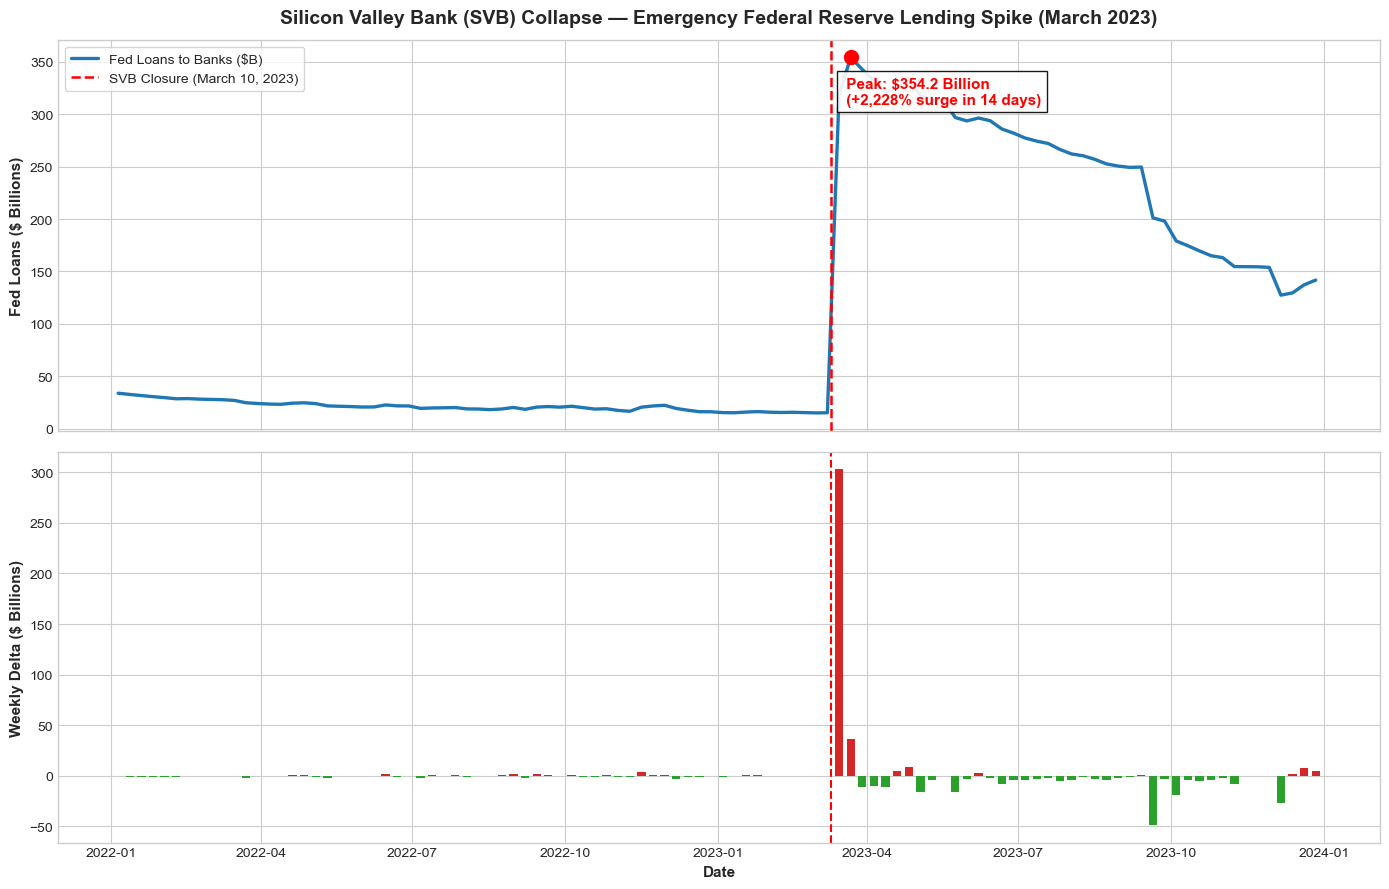

Saved clean Fed lending dataset to data/fed_emergency_lending_processed.csv


In [4]:
svb_date = pd.to_datetime('2023-03-10')

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

# 1. Macro Timeline of Fed Loans
axes[0].set_title("Silicon Valley Bank (SVB) Collapse — Emergency Federal Reserve Lending Spike (March 2023)", 
                  fontsize=14, fontweight='bold', pad=12)
axes[0].plot(df_fed_sub['observation_date'], df_fed_sub['fed_loans_billions'], color='#1f77b4', lw=2.4, label='Fed Loans to Banks ($B)')
axes[0].axvline(svb_date, color='red', ls='--', lw=1.8, label='SVB Closure (March 10, 2023)')
axes[0].scatter([peak_row['observation_date']], [peak_row['fed_loans_billions']], color='red', s=100, zorder=5)
axes[0].text(svb_date + pd.Timedelta(days=7), 310, f" Peak: $354.2 Billion\n (+2,228% surge in 14 days)", 
             fontsize=11, fontweight='bold', color='red', bbox=dict(facecolor='white', alpha=0.9))
axes[0].set_ylabel("Fed Loans ($ Billions)", fontsize=11, fontweight='bold')
axes[0].legend(loc='upper left', frameon=True)

# 2. Weekly Velocity (Delta y in Billions)
axes[1].bar(df_fed_sub['observation_date'], df_fed_sub['weekly_change_billions'], 
            color=np.where(df_fed_sub['weekly_change_billions'] >= 0, '#d62728', '#2ca02c'), width=5.0)
axes[1].axvline(svb_date, color='red', ls='--', lw=1.5)
axes[1].set_ylabel("Weekly Delta ($ Billions)", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Date", fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig('data/fed_emergency_lending_timeline.png', dpi=300)
plt.show()

# Export clean dataset
df_fed_sub.to_csv('data/fed_emergency_lending_processed.csv', index=False)
print("Saved clean Fed lending dataset to data/fed_emergency_lending_processed.csv")